In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## data-mixture

**Figure 1: Pretraining data mixture over training under our three-stage curriculum.** Each band is a domain's share of tokens; dashed lines mark the stage switches at 30K and 70K steps. The share of web text falls from 62% to 40% while code grows from 12% to 24% and math from 6% to 18%.

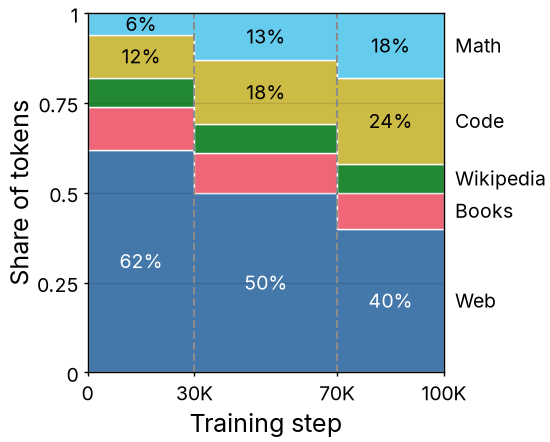

In [2]:
with open("../data/data-mixture.json") as f:
    data = json.load(f)
steps = np.array(data["steps"])
domains = ["Web", "Books", "Wikipedia", "Code", "Math"]
shares = np.array([data["shares"][d] for d in domains])
band_colors = [colors["series-1"], colors["series-2"], colors["series-3"], colors["series-4"], colors["series-5"]]
switches = [30000, 70000]
stages = [(0, 30000), (30000, 70000), (70000, 100000)]
cited = ["Web", "Code", "Math"]

fig, ax = plt.subplots(figsize=(2.75, 2.75))
ax.stackplot(steps, shares, colors=band_colors, labels=domains, step="post", edgecolor="white", linewidth=0.5)
for step in switches:
    ax.axvline(step, linestyle="--", linewidth=paper.dashed_width, color=colors["neutral"])

bottoms = np.vstack([np.zeros(len(steps)), np.cumsum(shares, axis=0)[:-1]])
for i, name in enumerate(domains):
    if name in cited:
        for start, end in stages:
            j = np.searchsorted(steps, start)
            ax.text((start + end) / 2, bottoms[i, j] + shares[i, j] / 2, f"{shares[i, j]:.0%}",
                    ha="center", va="center", color=text_color(band_colors[i]))
    ax.annotate(name, (1, bottoms[i, -1] + shares[i, -1] / 2), xycoords=("axes fraction", "data"),
                xytext=(4, 0), textcoords="offset points", va="center")

ax.set_xticks([0, *switches, 100000], labels=["0", "30K", "70K", "100K"])
ax.set_yticks([0, 0.25, 0.5, 0.75, 1], labels=["0", "0.25", "0.5", "0.75", "1"])
ax.set_ylim(0, 1)
ax.margins(x=0)
ax.set_axisbelow(False)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Training step")
ax.set_ylabel("Share of tokens")

fit_height(fig, ax, aspect=1.0)
fig.savefig("../outputs/data-mixture.pdf")
fig.savefig("../outputs/data-mixture.png")
plt.show()